# NLSB EB scRNA-seq — Curly-FM (port `ocean_currents_improved`)

**But** : construire les **trajectoires des cellules** grâce à Curly-FM,
en suivant strictement le pattern de `ocean_currents_improved.ipynb`
et `presentation.ipynb`.

**Données** : NLSB EB, on garde les **5 premières composantes** brutes (pas de PCA),
5 snapshots avec vélocité RNA.
**Protocole** : `train_ts = [0, 2, 4]`, `test_ts = [1, 3]`, **300 cellules / snapshot**.


In [1]:
# ===== Setup automatique : paquets + donnees (Colab / Kaggle / local) =====
import importlib.util, subprocess, sys, urllib.request
from pathlib import Path

# 1) Paquets manquants (torch, numpy, pandas, matplotlib, scipy, tqdm = deja la sur Colab/Kaggle)
for mod, pkg in [("torchcfm", "torchcfm"), ("torchdyn", "torchdyn")]:
    if importlib.util.find_spec(mod) is None:
        print(f"installing {pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

# 2) Racine : repo local si trouve, sinon dossier courant (Colab/Kaggle)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not ((ROOT/".git").exists() or (ROOT/"pyproject.toml").exists() or (ROOT/"setup.py").exists()):
    ROOT = ROOT.parent
if not ((ROOT/".git").exists() or (ROOT/"pyproject.toml").exists() or (ROOT/"setup.py").exists()):
    ROOT = Path.cwd().resolve()

# 3) Telechargement auto des donnees NLSB si absentes
DATA_DIR = ROOT / "data" / "nlsb"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE = "https://raw.githubusercontent.com/take-koshizuka/NLSB/main/data/"
for f in ["train_rna.npz", "val_rna.npz", "test_rna.npz"]:
    dst = DATA_DIR / f
    if not dst.exists():
        print(f"downloading {f} ...")
        urllib.request.urlretrieve(BASE + f, dst)
print("ROOT     :", ROOT)
print("DATA_DIR :", DATA_DIR)
print("files    :", sorted(p.name for p in DATA_DIR.glob("*.npz")))


installing torchcfm ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 77.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 kB 4.1 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cudf-cu12 26.2.1 requires numba-cuda[cu12]<0.23.0,>=0.22.2, but you hav

downloading train_rna.npz ...
downloading val_rna.npz ...
downloading test_rna.npz ...
ROOT     : /kaggle/working
DATA_DIR : /kaggle/working/data/nlsb
files    : ['test_rna.npz', 'train_rna.npz', 'val_rna.npz']


In [2]:
# ===== Auto-diagnostic : capture automatique des erreurs d'execution =====
import platform, traceback, datetime
import importlib.metadata as _ilm
from pathlib import Path as _Path

REPORT = (ROOT if "ROOT" in dir() else _Path.cwd()) / "run_report.txt"

def _pkg_versions():
    out = []
    for p in ["torch","torchcfm","torchdyn","torchsde","numpy",
              "scipy","pandas","matplotlib","pot"]:
        try:    out.append(f"  {p}=={_ilm.version(p)}")
        except Exception: out.append(f"  {p}==(absent)")
    try:
        import torch
        out.append(f"  cuda_available={torch.cuda.is_available()}")
        if torch.cuda.is_available():
            out.append(f"  gpu={torch.cuda.get_device_name(0)}")
    except Exception:
        pass
    return "\n".join(out)

with REPORT.open("w", encoding="utf-8") as fh:
    fh.write("NLSB Curly-FM -- run report\n")
    fh.write(f"date   : {datetime.datetime.now():%Y-%m-%d %H:%M:%S}\n")
    fh.write(f"python : {platform.python_version()} | {platform.platform()}\n")
    fh.write("packages:\n" + _pkg_versions() + "\n")
    fh.write("status : EN COURS...\n")

# Mouchard non-intrusif : journalise toute erreur de cellule SANS la masquer
# (l'erreur s'affiche normalement ET nbconvert/Colab s'arretent comme d'habitude).
_ip = get_ipython()
if _ip is not None:
    def _log_cell_error(result):
        err = getattr(result, "error_in_exec", None)
        if err is not None:
            with REPORT.open("a", encoding="utf-8") as fh:
                fh.write("\n!!! ERREUR D'EXECUTION !!!\n")
                fh.write("".join(traceback.format_exception(
                    type(err), err, err.__traceback__)))
            print("\n>>> Erreur enregistree dans", REPORT.name,
                  "-- telecharge ce fichier et envoie-le moi.")
    _ip.events.register("post_run_cell", _log_cell_error)
    print("Auto-diagnostic actif. Rapport ->", REPORT)


Auto-diagnostic actif. Rapport -> /kaggle/working/run_report.txt


In [3]:
import os, time
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import torch
from torchdyn.core import NeuralODE
from tqdm import tqdm

from torchcfm import optimal_transport
from torchcfm.conditional_flow_matching import *
from torchcfm.models import MLP
from torchcfm.utils import plot_trajectories, torch_wrapper


2026-06-14 12:44:30.909267: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781441071.084690      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781441071.133180      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781441071.528800      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781441071.528849      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781441071.528852      58 computation_placer.cc:177] computation placer alr

In [4]:
# set seed
torch.manual_seed(0)
np.random.seed(0)


In [5]:
# set device — GPU impératif (consigne chef de projet)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type != "cuda":
    print("WARNING: pas de GPU detecte -> execution CPU (lente).")
    print("         Lancer ce notebook sur un serveur GPU pour la config complete.")
print("device:", device)


device: cuda


In [6]:
# ===== Config entrainement (consigne chef de projet) =====
KEEP_DIMS = 5      # garder uniquement les 5 premieres composantes (PAS de PCA)
VIZ_DIMS  = 3      # visualiser avec les 3 premieres composantes
N_TRACK   = 300    # 300 cellules par snapshot
BATCH     = 256    # batch plus grand (etait 64)
LR        = 5e-4   # learning rate un peu plus grand (etait 1e-4)
N_ITERS   = 3000   # jusqu'a 3000 iterations
print(f"KEEP_DIMS={KEEP_DIMS}  N_TRACK={N_TRACK}  BATCH={BATCH}  LR={LR}  N_ITERS={N_ITERS}")


KEEP_DIMS=5  N_TRACK=300  BATCH=256  LR=0.0005  N_ITERS=3000


## Chargement NLSB EB


In [7]:
# load NLSB data (3 npz files pooled, then regrouped by snapshot)
# ROOT et DATA_DIR sont definis dans la cellule de Setup (haut du notebook)
Xs, Vs, Ts = [], [], []
for f in ["train_rna.npz", "val_rna.npz", "test_rna.npz"]:
    npz = np.load(DATA_DIR / f)
    Xs.append(npz["X"]); Vs.append(npz["v"]); Ts.append(npz["ts"])
X_pool = np.concatenate(Xs, 0).astype(np.float32)
V_pool = np.concatenate(Vs, 0).astype(np.float32)
ts_pool = np.concatenate(Ts, 0).astype(np.int64)

# Consigne chef de projet : PAS de PCA. On ne garde que les KEEP_DIMS
# premieres composantes brutes du dataset.
X_pool = X_pool[:, :KEEP_DIMS]
V_pool = V_pool[:, :KEEP_DIMS]

# StandardScaler fitté sur les snapshots train uniquement (convention NLSB)
TRAIN_TS = [0, 2, 4]
TEST_TS  = [1, 3]
mask_tr = np.isin(ts_pool, TRAIN_TS)
mean = X_pool[mask_tr].mean(0, keepdims=True)
scale = X_pool[mask_tr].std(0, keepdims=True); scale[scale == 0] = 1
X_pool = (X_pool - mean) / scale
V_pool = V_pool / scale       # v /= scale (convention NLSB)

# Pour pouvoir stack en (num_times, num_particles, d) comme ocean_currents,
# on sous-échantillonne chaque snapshot à N_TRACK cellules (cf config).
rng = np.random.RandomState(0)

positions, velocities = [], []
for t in range(5):
    idx_t = np.where(ts_pool == t)[0]
    idx = rng.choice(idx_t, size=N_TRACK, replace=False)
    positions.append(X_pool[idx])
    velocities.append(V_pool[idx])
positions  = np.stack(positions, axis=0).astype(np.float32)   # (5, N_TRACK, 100)
velocities = np.stack(velocities, axis=0).astype(np.float32)
print("positions :", positions.shape)
print("velocities:", velocities.shape)

num_times    = positions.shape[0]
num_particles= positions.shape[1]
d            = positions.shape[-1]
k = 30        # knn number pour la regression de vitesse


positions : (5, 300, 5)
velocities: (5, 300, 5)


## Analyse exploratoire 

> *« First of all, analyse the data — find some statistics about cell counts per snapshot, plot etc. »*


In [8]:
# Stats par snapshot
stats = []
for t in range(num_times):
    Xt = positions[t]; Vt = velocities[t]
    n_total = int((ts_pool == t).sum())  # nombre réel de cellules dans le dataset complet
    stats.append({
        "snap": t,
        "rôle": "train" if t in TRAIN_TS else "test",
        "n_cells_total": n_total,
        "n_cells_tracked": Xt.shape[0],
        "||x||_moy": float(np.linalg.norm(Xt, axis=1).mean()),
        "||v||_moy": float(np.linalg.norm(Vt, axis=1).mean()),
    })
df_stats = pd.DataFrame(stats)
df_stats


,snap,rôle,n_cells_total,n_cells_tracked,||x||_moy,||v||_moy
0,0,train,2381,300,2.197693,0.022980
1,1,test,4163,300,1.755347,0.018577
2,2,train,3278,300,1.852787,0.026233
3,3,test,3665,300,1.952975,0.021374
4,4,train,3332,300,2.278067,0.021031


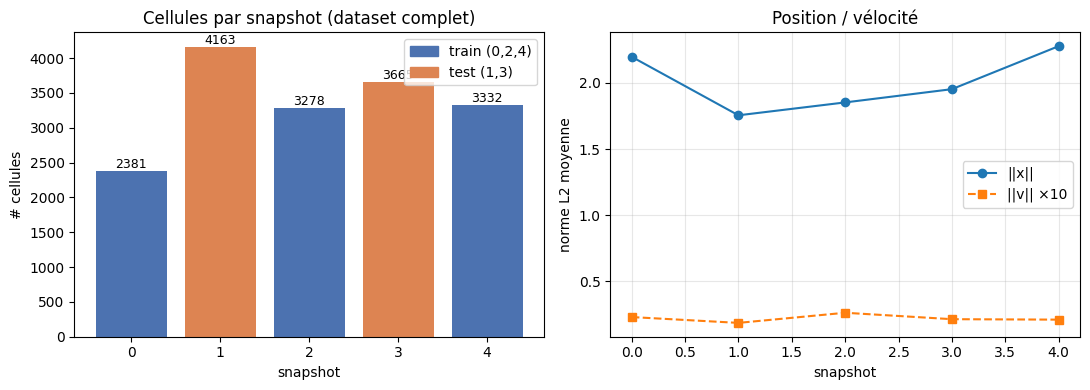

In [9]:
# Plot cell counts (toutes les cellules du dataset, pas seulement les tracées)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cols = ["#4c72b0" if r == "train" else "#dd8452" for r in df_stats["rôle"]]
axes[0].bar(df_stats["snap"], df_stats["n_cells_total"], color=cols)
for _, row in df_stats.iterrows():
    axes[0].text(row["snap"], row["n_cells_total"], str(row["n_cells_total"]),
                 ha="center", va="bottom", fontsize=9)
axes[0].set_xlabel("snapshot"); axes[0].set_ylabel("# cellules")
axes[0].set_title("Cellules par snapshot (dataset complet)")
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color="#4c72b0", label="train (0,2,4)"),
                        Patch(color="#dd8452", label="test (1,3)")])

axes[1].plot(df_stats["snap"], df_stats["||x||_moy"], "o-", label="||x||")
axes[1].plot(df_stats["snap"], df_stats["||v||_moy"]*10, "s--", label="||v|| ×10")
axes[1].set_xlabel("snapshot"); axes[1].set_ylabel("norme L2 moyenne")
axes[1].set_title("Position / vélocité"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


## Visualisation 3D (3 premières composantes)

**pas de PCA**. On travaille directement sur les
`KEEP_DIMS = 5` premières composantes brutes et on visualise avec les
`VIZ_DIMS = 3` premières (plots 3D).


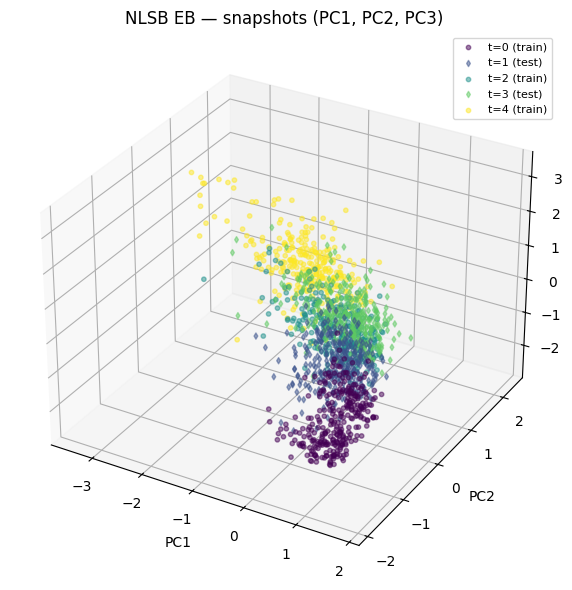

In [10]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (active la projection 3D)

def to3d(x):
    '''Garde les VIZ_DIMS premieres composantes pour la visualisation.'''
    if isinstance(x, torch.Tensor): x = x.cpu().numpy()
    return x[..., :VIZ_DIMS]

# Vue d'ensemble : snapshots sur les 3 premieres composantes
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
colors = plt.cm.viridis(np.linspace(0, 1, num_times))
for t in range(num_times):
    p = positions[t][:, :VIZ_DIMS]
    role = "train" if t in TRAIN_TS else "test"
    marker = "o" if t in TRAIN_TS else "d"
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=[colors[t]], s=10, alpha=0.5,
               marker=marker, label=f"t={t} ({role})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("NLSB EB — snapshots (PC1, PC2, PC3)")
ax.legend(fontsize=8, loc="best")
plt.tight_layout(); plt.show()


## Split train / test 

> *« You have to consider snapshots 0,2,4 as training and 1,3 as validation. »*


In [11]:
x_train, v_train = [], []
x_test, v_test = [], []

for t in range(num_times):
    if t in TRAIN_TS:
        x_train.append(positions[t]);  v_train.append(velocities[t])
    elif t in TEST_TS:
        x_test.append(positions[t]);   v_test.append(velocities[t])

x_train = np.stack(x_train);  v_train = np.stack(v_train)
x_test  = np.stack(x_test);   v_test  = np.stack(v_test)
print("train:", x_train.shape, v_train.shape)
print("test :", x_test.shape, v_test.shape)


train: (3, 300, 5) (3, 300, 5)
test : (2, 300, 5) (2, 300, 5)


## Helpers — copie depuis `ocean_currents_improved.ipynb`


In [12]:
def get_batch(FM_module, X, batch_size, n_times, ts_train, return_noise=False):
    '''Construct a batch with points from each timepoint pair (port from ocean_currents).'''
    ts, xts, uts, noises = [], [], [], []
    for t_start in range(len(ts_train) - 1):
        t_end = t_start + 1
        x0 = (torch.from_numpy(X[t_start][np.random.randint(X[t_start].shape[0], size=batch_size)])
              .float().to(device))
        x1 = (torch.from_numpy(X[t_end][np.random.randint(X[t_end].shape[0], size=batch_size)])
              .float().to(device))
        if return_noise:
            t, xt, ut, eps = FM_module.sample_location_and_conditional_flow(x0, x1, return_noise=True)
            noises.append(eps)
        else:
            t, xt, ut = FM_module.sample_location_and_conditional_flow(x0, x1, return_noise=False)
        ts.append(t + t_start); xts.append(xt); uts.append(ut)
    t = torch.cat(ts); xt = torch.cat(xts); ut = torch.cat(uts)
    if return_noise:
        return t, xt, ut, torch.cat(noises)
    return t, xt, ut


In [13]:
# Mapping snapshot index dans positions <-> position relative dans train_ts
# Pour le segment t (entre train_ts[t] et train_ts[t+1]), le held-out est test_ts[t]
for t in range(len(TRAIN_TS) - 1):
    print(t, t + 1/2, "—  train", TRAIN_TS[t], "→ test", TEST_TS[t], "→ train", TRAIN_TS[t+1])


0 0.5 —  train 0 → test 1 → train 2
1 1.5 —  train 2 → test 3 → train 4


In [14]:
def get_ut_knn_gaussian(xt, x0, x1, v0, v1, k=100, eps=1e-12):
    '''Gaussian-weighted k-NN regression of RNA velocity onto xt — paper helper.'''
    x = torch.cat([x0, x1], dim=0)
    v = torch.cat([v0, v1], dim=0)
    dists = torch.cdist(xt, x)
    knn_dists, knn_idx = torch.topk(dists, k=k, dim=1, largest=False)
    h = knn_dists[:, -1:].clamp_min(eps)
    w = torch.exp(-(knn_dists**2) / (2 * h**2))
    w = w / (w.sum(dim=1, keepdim=True) + eps)
    v_knn = v[knn_idx]
    return (w.unsqueeze(-1) * v_knn).sum(dim=1)


## Calibrage de l'échelle vitesse → déplacement

La **vitesse RNA** et le **déplacement entre snapshots** ne sont pas dans les
mêmes unités (ratio ~100–200× sur NLSB en 5D). Sans correction, le terme L2 de la
loss géodésique `(alpha·u_t − mu_t_dot)²` est entièrement dominé par le déplacement
et **ne peut pas décroître** (une trajectoire ne peut pas avoir une vitesse moyenne
de 0.03 si ses extrémités sont distantes de ~3). Le couplage hongrois souffre du
même problème. On calibre donc `VEL_SCALE` (= `alpha`) directement sur les données.


In [15]:
# Echelle vitesse -> deplacement, mesuree sur les paires de snapshots train.
# (Au depart la geodesique est ~lineaire : mu_t_dot ~ x1 - x0.)
with torch.no_grad():
    _disp, _vn = [], []
    for t in range(len(TRAIN_TS) - 1):
        x0 = torch.from_numpy(x_train[t]).float().to(device)
        x1 = torch.from_numpy(x_train[t + 1]).float().to(device)
        v0 = torch.from_numpy(v_train[t]).float().to(device)
        v1 = torch.from_numpy(v_train[t + 1]).float().to(device)
        tt = torch.rand(x0.shape[0], 1, device=device)
        xt_lin = (1 - tt) * x0 + tt * x1
        ut = get_ut_knn_gaussian(xt_lin, x0, x1, v0, v1, k=k)
        _disp.append((x1 - x0).norm(dim=1).mean())
        _vn.append(ut.norm(dim=1).mean())
VEL_SCALE = float(torch.stack(_disp).mean() / torch.stack(_vn).mean().clamp_min(1e-8))
print(f"VEL_SCALE (alpha calibre sur donnees) = {VEL_SCALE:.1f}")


VEL_SCALE (alpha calibre sur donnees) = 204.3


In [16]:
import torch.nn.functional as F

class CurlyWrapperWithMetrics(torch.nn.Module):
    '''Augmented integrand : returns [x_dot, cos-dist, L2-cost] for tracking along path.

    Note : u_t est mis a l'echelle par VEL_SCALE (calibre sur donnees) pour que
    les metriques cos/L2 soient comparables a x_dot (cf cellule de calibrage).
    '''
    def __init__(self, model, x0, x1, v0, v1, k):
        super().__init__()
        self.model = model
        self.x0 = x0; self.x1 = x1; self.v0 = v0; self.v1 = v1; self.k = k

    def forward(self, t, z, *args, **kwargs):
        x = z[:, :-2]
        x_dot = self.model(torch.cat([x, t.repeat(x.shape[0])[:, None]], dim=1))
        u_t = VEL_SCALE * get_ut_knn_gaussian(x, self.x0, self.x1, self.v0, self.v1, k=self.k)
        cos_dist = 1 - F.cosine_similarity(u_t, x_dot, dim=1)
        L2_squared = torch.sum((u_t - x_dot) ** 2, dim=1)
        return torch.cat([x_dot, cos_dist.unsqueeze(1), L2_squared.unsqueeze(1)], dim=1)


In [17]:
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from mpl_toolkits.mplot3d.art3d import Line3DCollection

TRAJ_CMAP = plt.cm.viridis   # palette perceptuellement uniforme (standard publication)

def _style_3d(ax):
    '''Fond epure facon publication : panneaux blancs, grille discrete.'''
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_facecolor("white"); axis.pane.set_edgecolor("0.85")
        axis.pane.set_alpha(1.0)
    ax.grid(True, alpha=0.25)

def _draw_traj_panel(ax, positions, traj, ts_train=None, ts_test=None,
                     num_trajectories=80, show_points=True, cmap=TRAJ_CMAP,
                     elev=18, azim=-72):
    '''Un panneau 3D : points en contexte discret (arriere-plan) +
    trajectoires en streamlines colorees par le temps, au PREMIER plan (halo blanc).
    Retourne la collection coloree (pour la colorbar).'''
    vmax = positions.shape[0] - 1
    norm = Normalize(vmin=0, vmax=vmax)

    # --- arriere-plan : nuage de points, subtil (zorder bas) ---
    if show_points:
        for grp, marker, a, sz in [(ts_train, "o", 0.13, 6), (ts_test, "d", 0.18, 8)]:
            if not grp:
                continue
            for ti in grp:
                p = positions[ti][:, :VIZ_DIMS]
                ax.scatter(p[:, 0], p[:, 1], p[:, 2], color=cmap(norm(ti)), s=sz,
                           alpha=a, marker=marker, depthshade=False,
                           edgecolors="none", zorder=1)

    # --- premier plan : trajectoires en streamlines colorees par le temps ---
    traj_3d = to3d(traj)                          # (T, N_traj, 3)
    T, N_traj, _ = traj_3d.shape
    tline = np.linspace(0, vmax, T)               # temps logique -> echelle snapshot
    sel = np.linspace(0, N_traj - 1, min(num_trajectories, N_traj)).astype(int)
    segs, segc = [], []
    for i in sel:
        pts = traj_3d[:, i, :]
        segs.extend(np.stack([pts[:-1], pts[1:]], axis=1))   # (T-1, 2, 3)
        segc.extend(0.5 * (tline[:-1] + tline[1:]))
    segs = np.asarray(segs); segc = np.asarray(segc)
    # halo blanc -> les lignes "ressortent" nettement par-dessus les points
    ax.add_collection3d(Line3DCollection(segs, colors="white", linewidths=3.4,
                                         alpha=0.6, zorder=2))
    lc = Line3DCollection(segs, cmap=cmap, norm=norm, linewidths=1.8,
                          alpha=0.95, zorder=3)
    lc.set_array(segc); ax.add_collection3d(lc)

    # limites manuelles (add_collection3d ne rescale pas l'axe 3D)
    parts = [traj_3d[:, sel, :].reshape(-1, 3)]
    for grp in (ts_train, ts_test):
        if grp:
            for ti in grp:
                parts.append(positions[ti][:, :VIZ_DIMS])
    allp = np.concatenate(parts, 0)
    lo, hi = allp.min(0), allp.max(0); pad = 0.05 * (hi - lo + 1e-9)
    ax.set_xlim(lo[0]-pad[0], hi[0]+pad[0]); ax.set_ylim(lo[1]-pad[1], hi[1]+pad[1])
    ax.set_zlim(lo[2]-pad[2], hi[2]+pad[2])
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
    ax.view_init(elev=elev, azim=azim); _style_3d(ax)
    return lc

def plot_trajectories_on_data(positions, traj, num_trajectories=80, ts_train=None,
                              ts_test=None, elev=18, azim=-72, title=None):
    '''Version publication, 1 panneau (points discrets + streamlines au 1er plan).'''
    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(111, projection="3d")
    lc = _draw_traj_panel(ax, positions, traj, ts_train, ts_test,
                          num_trajectories=num_trajectories, elev=elev, azim=azim)
    legend_elements = [
        Line2D([0], [0], marker='o', linestyle="None", color='0.5', label='Train', markersize=6),
        Line2D([0], [0], marker='d', linestyle="None", color='0.5', label='Test', markersize=6),
    ]
    ax.legend(handles=legend_elements, loc="upper left", markerscale=1.3, framealpha=0.9)
    if title:
        ax.set_title(title, fontsize=12)
    cbar = fig.colorbar(lc, ax=ax, shrink=0.6, pad=0.1); cbar.set_label("$t$ (snapshot)")
    plt.tight_layout(); plt.show()


## OT-CFM (baseline)


In [18]:
batch_size = BATCH      # consigne chef : batch plus grand
sigma = 0.05            # ocean_currents_improved
dim = d
ot_cfm_model = MLP(dim=dim, time_varying=True, w=128).to(device)
ot_cfm_optimizer = torch.optim.Adam(ot_cfm_model.parameters(), LR)  # LR plus grand
FM = ExactOptimalTransportConditionalFlowMatcher(sigma=sigma)


OT-CFM: 100%|██████████| 3000/3000 [01:22<00:00, 36.44it/s]


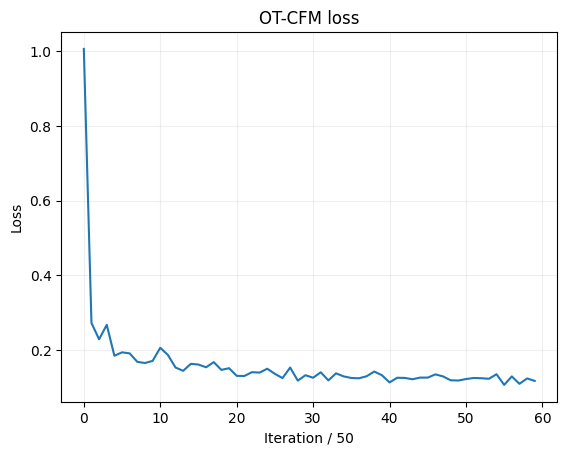

In [19]:
loss_otcfm = []
start_time = time.time()

for i in tqdm(range(N_ITERS), desc="OT-CFM"):
    ot_cfm_optimizer.zero_grad()
    t, xt, ut = get_batch(FM, x_train, batch_size, num_times, TRAIN_TS)
    vt = ot_cfm_model(torch.cat([xt, t[:, None]], dim=-1))
    loss = torch.mean((vt - ut) ** 2)
    loss.backward()
    ot_cfm_optimizer.step()
    if i % 50 == 0:
        loss_otcfm.append(loss.cpu().item())

train_time_ot_cfm = time.time() - start_time
plt.plot(loss_otcfm); plt.grid(alpha=0.2)
plt.xlabel("Iteration / 50"); plt.ylabel("Loss"); plt.title("OT-CFM loss")
plt.show()


### Trajectoires OT-CFM construites + métriques sur held-out

Pour CHAQUE segment train (0→2, 2→4) :
- Construire la trajectoire complète de `t` à `t+1` (logical) en intégrant le velocity field.
- Évaluer aux held-out : intégrer de `t` à `t + 1/2`, comparer le endpoint au snapshot test correspondant.


Avg Cosine distance: 0.2603849545121193
Avg L2 cost       : 4.126082420349121
Avg Wass-1 distance: 0.8902444685747222

t          Cosine-dist    &      L2 cost       &       Wass-1
t1 (held-out) --- 0.3479 & 5.8893 & 0.7856 \\
t3 (held-out) --- 0.1729 & 2.3629 & 0.9949 \\

OT-CFM training time -- 1:22 (mins:secs)


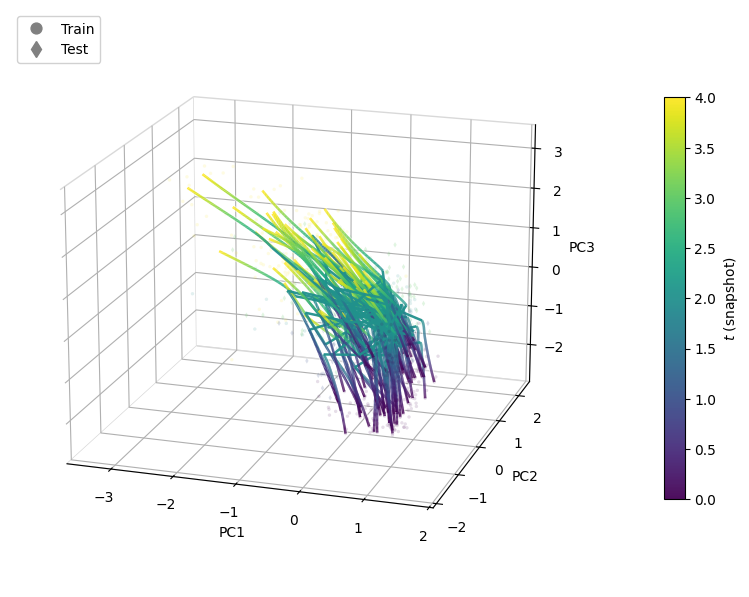

In [20]:
with torch.no_grad():
    # ======== 1) Construction des trajectoires complètes (port ocean_currents) ========
    trajs = []
    for t in range(len(TRAIN_TS) - 1):
        x0 = torch.from_numpy(x_train[t]).float().to(device)
        x1 = torch.from_numpy(x_train[t + 1]).float().to(device)
        v0 = torch.from_numpy(v_train[t]).float().to(device)
        v1 = torch.from_numpy(v_train[t + 1]).float().to(device)

        wrapped = CurlyWrapperWithMetrics(ot_cfm_model, x0, x1, v0, v1, k)
        node = NeuralODE(wrapped, solver="euler", sensitivity="adjoint")
        z0 = torch.cat([x0, torch.zeros(x0.shape[0], 2, device=x0.device)], dim=1)
        out = node.trajectory(z0, t_span=torch.linspace(t, t+1, 100)).cpu()
        trajs.append(out[:, :, :-2])

    traj_ot_cfm = torch.cat(trajs, dim=0)

    # ======== 2) Métriques sur held-out (snap 1 entre train 0,2 — snap 3 entre train 2,4) ========
    wass1, cos_dist, L2_cost = [], [], []
    for t, t_train in enumerate(TRAIN_TS[:-1]):
        # held-out: TEST_TS[t] (snap 1 entre train 0 et train 2, etc.)
        held_out_snap = TEST_TS[t]
        x0 = torch.from_numpy(positions[t_train]).float().to(device)
        x1 = torch.from_numpy(positions[held_out_snap]).float().to(device)
        v0 = torch.from_numpy(velocities[t_train]).float().to(device)
        v1 = torch.from_numpy(velocities[held_out_snap]).float().to(device)

        wrapped = CurlyWrapperWithMetrics(ot_cfm_model, x0, x1, v0, v1, k)
        node = NeuralODE(wrapped, solver="euler", sensitivity="adjoint")
        z0 = torch.cat([x0, torch.zeros(x0.shape[0], 2, device=x0.device)], dim=1)
        pred_out = node.trajectory(z0, t_span=torch.linspace(t, t + 1/2, 100)).cpu()

        pred_traj = pred_out[:, :, :-2]
        cosine_traj = pred_out[:, :, -2]
        L2_traj = pred_out[:, :, -1]
        pred = pred_traj[-1]

        cos_dist.append(float(cosine_traj[-1].mean()))
        L2_cost.append(float(L2_traj[-1].mean()))
        wass1.append(float(optimal_transport.wasserstein(pred, x1.cpu(), power=1)))

    cos_dist = np.array(cos_dist); L2_cost = np.array(L2_cost); wass1 = np.array(wass1)
    print("Avg Cosine distance:", cos_dist.mean())
    print("Avg L2 cost       :", L2_cost.mean())
    print("Avg Wass-1 distance:", wass1.mean())
    print()
    print("t          Cosine-dist    &      L2 cost       &       Wass-1")
    for i, ho in enumerate(TEST_TS):
        print(f"t{ho} (held-out) --- {cos_dist[i]:.4f} & {L2_cost[i]:.4f} & {wass1[i]:.4f} \\\\")
    m, s = divmod(int(train_time_ot_cfm), 60)
    print(f"\nOT-CFM training time -- {m}:{s:02d} (mins:secs)")

    plot_trajectories_on_data(positions, traj_ot_cfm.cpu().numpy(),
                              num_trajectories=80, ts_train=TRAIN_TS, ts_test=TEST_TS)

# Sauvegarde
res_ot = pd.DataFrame({"model": "OT-CFM", "held_out_snap": TEST_TS,
                       "W1": wass1, "cos": cos_dist, "L2": L2_cost})


## Curly-FM


In [21]:
from torch.func import vmap
import scipy

def get_xt(t, t_start, x0, x1, geodesic_model, sigma=0.0):
    mu_t = (1 - t) * x0 + t * x1 + t * (1-t) * (geodesic_model(torch.cat([x0, x1, t+t_start], dim=-1)))
    epsilon = torch.randn_like(x0)
    x_t = mu_t + torch.sqrt(t*(1-t))*sigma * epsilon
    return mu_t, x_t, epsilon

def get_xt_xt_dot(t, t_start, t_end, x0, x1, geodesic_model, sigma=0.0):
    with torch.enable_grad():
        t = t[..., None]; t.requires_grad_(True)
        mu_t, xt, eps = get_xt(t, t_start, x0, x1, geodesic_model, sigma=sigma)
        mu_t_dot_list = []
        for i in range(xt.shape[-1]):
            mu_t_dot_list.append(
                torch.autograd.grad(torch.sum(mu_t[..., i]), t, create_graph=True)[0]
            )
        mu_t_dot = torch.cat(mu_t_dot_list, -1)
    return xt, mu_t_dot, eps

def coupling_geo_new(t_start, t_end, x0, x1, x0s, x1s, v0s, v1s, geodesic_model, k, sigma):
    '''Hungarian assignment coupling.'''
    batch_size, dd = x0.shape
    t = torch.rand(1).type_as(x0) * torch.ones((batch_size, batch_size), device=x0.device)
    x0_r = x0.repeat(batch_size, 1, 1)
    x1_r = x1.repeat(batch_size, 1, 1).transpose(0, 1)
    xt, mu_t_dot, eps = get_xt_xt_dot(t, t_start, t_end, x0_r, x1_r, geodesic_model, sigma)
    ut = vmap(lambda x: get_ut_knn_gaussian(x, x0s, x1s, v0s, v1s, k=k))(xt)
    L2_cost = 0.5 * ((mu_t_dot.detach() - VEL_SCALE * ut) ** 2).sum(-1)
    _, j = scipy.optimize.linear_sum_assignment(L2_cost.detach().cpu().numpy())
    return x0[j], x1, eps


In [22]:
def get_batch_geo(geo, X, V, batch_size, sigma, ts_train):
    '''Construct a Curly-geo batch — port from ocean_currents_improved.'''
    ts, t_orig_list, mu_t_dots, eps_list, xts, uts = [], [], [], [], [], []
    for t_start in range(len(ts_train) - 1):
        t_end = t_start + 1
        idcs_0 = np.random.randint(X[t_start].shape[0], size=batch_size)
        idcs_1 = np.random.randint(X[t_end].shape[0],   size=batch_size)
        x0 = torch.from_numpy(X[t_start][idcs_0]).float().to(device)
        x1 = torch.from_numpy(X[t_end][idcs_1]).float().to(device)
        v0 = torch.from_numpy(V[t_start][idcs_0]).float().to(device)
        v1 = torch.from_numpy(V[t_end][idcs_1]).float().to(device)
        t = torch.rand(x0.shape[0]).type_as(x0); t_o = t
        xt, mu_t_dot, eps = get_xt_xt_dot(t, t_start, t_end, x0, x1, geo, sigma=sigma)
        ut = get_ut_knn_gaussian(xt, x0, x1, v0, v1, k=k)
        xt = xt + torch.sqrt(t * (1-t)).unsqueeze(1) * sigma * eps
        t_orig_list.append(t_o); ts.append(t + t_start); xts.append(xt)
        uts.append(ut); mu_t_dots.append(mu_t_dot); eps_list.append(eps)
    return (torch.cat(t_orig_list), torch.cat(ts), torch.cat(xts),
            torch.cat(uts), torch.cat(mu_t_dots), torch.cat(eps_list))


In [23]:
batch_size = BATCH
sigma = 0.05            # ocean_currents_improved
alpha = VEL_SCALE       # calibre sur donnees (vitesse RNA != echelle deplacement)
geo_model = MLP(dim=dim*2, out_dim=dim, time_varying=True, w=128).to(device)
geo_optimizer = torch.optim.AdamW(geo_model.parameters(), LR, weight_decay=1e-3)


Curly-FM geo: 100%|██████████| 3000/3000 [01:12<00:00, 41.31it/s]


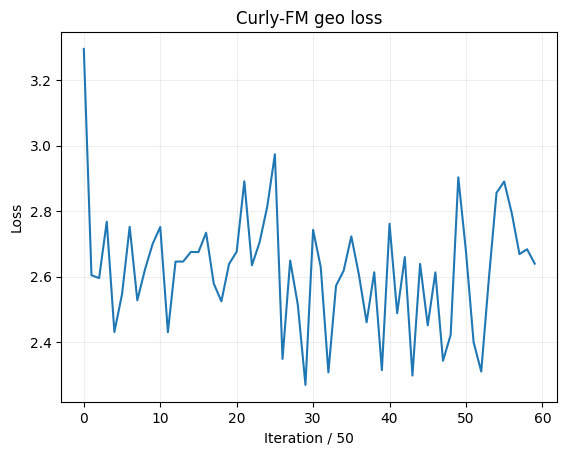

In [24]:
train_loss = []
start_time = time.time()

for i in tqdm(range(N_ITERS), desc="Curly-FM geo"):
    geo_optimizer.zero_grad()
    t_orig, t, xt, ut, mu_t_dot, eps = get_batch_geo(
        geo_model, x_train, v_train, batch_size, sigma, TRAIN_TS
    )
    cosine_loss = 1 - F.cosine_similarity(ut, mu_t_dot).mean()
    loss = torch.mean((alpha*ut - mu_t_dot) ** 2) + cosine_loss
    loss.backward()
    geo_optimizer.step()
    if i % 50 == 0: train_loss.append(loss.cpu().item())

train_time_curly_geo = time.time() - start_time
plt.plot(train_loss); plt.grid(alpha=0.2)
plt.xlabel("Iteration / 50"); plt.ylabel("Loss"); plt.title("Curly-FM geo loss")
plt.show()


In [25]:
def get_batch_vel(geo, X, V, batch_size, sigma, ts_train):
    ts, t_orig_list, mu_t_dots, eps_list, xts = [], [], [], [], []
    for t_start in range(len(ts_train) - 1):
        t_end = t_start + 1
        idcs_0 = np.random.randint(X[t_start].shape[0], size=batch_size)
        idcs_1 = np.random.randint(X[t_end].shape[0],   size=batch_size)
        x0 = torch.from_numpy(X[t_start][idcs_0]).float().to(device)
        x1 = torch.from_numpy(X[t_end][idcs_1]).float().to(device)
        v0 = torch.from_numpy(V[t_start][idcs_0]).float().to(device)
        v1 = torch.from_numpy(V[t_end][idcs_1]).float().to(device)
        t = torch.rand(x0.shape[0]).type_as(x0); t_o = t
        x0, x1, _ = coupling_geo_new(t_start, t_end, x0, x1, x0, x1, v0, v1, geo, k, sigma=sigma)
        xt, mu_t_dot, eps = get_xt_xt_dot(t, t_start, t_end, x0, x1, geo, sigma=sigma)
        t_orig_list.append(t_o); ts.append(t + t_start)
        xts.append(xt); mu_t_dots.append(mu_t_dot); eps_list.append(eps)
    return (torch.cat(t_orig_list), torch.cat(ts), torch.cat(xts),
            torch.cat(mu_t_dots), torch.cat(eps_list))


In [26]:
batch_size = BATCH
sigma = 0.05
alpha = VEL_SCALE
vel_model = MLP(dim=dim, time_varying=True, w=128).to(device)
vel_optimizer = torch.optim.AdamW(vel_model.parameters(), LR, weight_decay=1e-3)


Curly-FM vel: 100%|██████████| 3000/3000 [05:22<00:00,  9.29it/s]


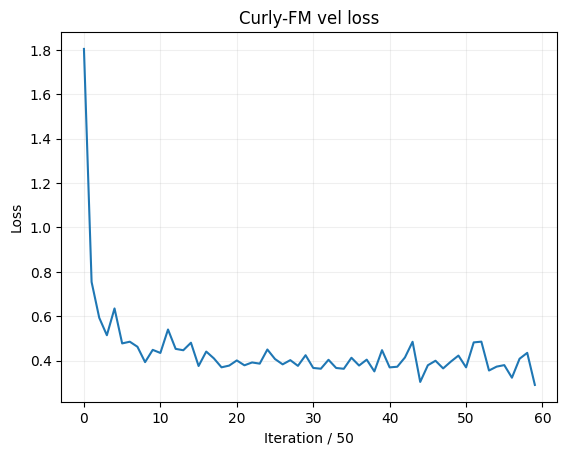

In [27]:
vel_loss = []
start_time = time.time()

for i in tqdm(range(N_ITERS), desc="Curly-FM vel"):
    vel_optimizer.zero_grad()
    t_orig, t, xt, mu_t_dot, eps = get_batch_vel(
        geo_model, x_train, v_train, batch_size, sigma, TRAIN_TS
    )
    vt = vel_model(torch.cat([xt.detach(), t[:, None]], dim=-1))
    loss = torch.mean((vt - mu_t_dot.detach()) ** 2)
    loss.backward()
    vel_optimizer.step()
    if i % 50 == 0: vel_loss.append(loss.cpu().item())

train_time_curly_vel = time.time() - start_time
plt.plot(vel_loss); plt.grid(alpha=0.2)
plt.xlabel("Iteration / 50"); plt.ylabel("Loss"); plt.title("Curly-FM vel loss")
plt.show()


### Trajectoires Curly-FM construites + métriques sur held-out


Avg Cosine distance: 0.1484214961528778
Avg L2 cost       : 2.2100788950920105
Avg Wass-1 distance: 0.9460286636153858

t          Cosine-dist    &      L2 cost       &       Wass-1
t1 (held-out) --- 0.1568 & 2.4784 & 0.8988 \\
t3 (held-out) --- 0.1400 & 1.9418 & 0.9932 \\

Curly-FM training time -- 6:35 (mins:secs)


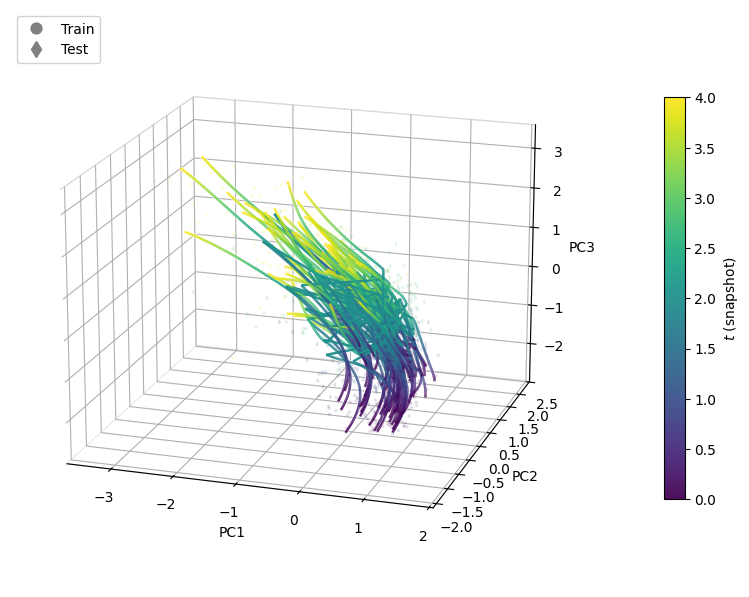

In [28]:
with torch.no_grad():
    # ======== 1) Construction des trajectoires complètes ========
    trajs = []
    for t in range(len(TRAIN_TS) - 1):
        x0 = torch.from_numpy(x_train[t]).float().to(device)
        x1 = torch.from_numpy(x_train[t + 1]).float().to(device)
        v0 = torch.from_numpy(v_train[t]).float().to(device)
        v1 = torch.from_numpy(v_train[t + 1]).float().to(device)

        wrapped = CurlyWrapperWithMetrics(vel_model, x0, x1, v0, v1, k)
        node = NeuralODE(wrapped, solver="euler", sensitivity="adjoint")
        z0 = torch.cat([x0, torch.zeros(x0.shape[0], 2, device=x0.device)], dim=1)
        out = node.trajectory(z0, t_span=torch.linspace(t, t+1, 100)).cpu()
        trajs.append(out[:, :, :-2])

    traj_curly = torch.cat(trajs, dim=0)

    # ======== 2) Métriques sur held-out ========
    wass1, cos_dist, L2_cost = [], [], []
    for t, t_train in enumerate(TRAIN_TS[:-1]):
        held_out_snap = TEST_TS[t]
        x0 = torch.from_numpy(positions[t_train]).float().to(device)
        x1 = torch.from_numpy(positions[held_out_snap]).float().to(device)
        v0 = torch.from_numpy(velocities[t_train]).float().to(device)
        v1 = torch.from_numpy(velocities[held_out_snap]).float().to(device)

        wrapped = CurlyWrapperWithMetrics(vel_model, x0, x1, v0, v1, k)
        node = NeuralODE(wrapped, solver="euler", sensitivity="adjoint")
        z0 = torch.cat([x0, torch.zeros(x0.shape[0], 2, device=x0.device)], dim=1)
        pred_out = node.trajectory(z0, t_span=torch.linspace(t, t + 1/2, 100)).cpu()

        pred_traj = pred_out[:, :, :-2]
        cosine_traj = pred_out[:, :, -2]
        L2_traj = pred_out[:, :, -1]
        pred = pred_traj[-1]

        cos_dist.append(float(cosine_traj[-1].mean()))
        L2_cost.append(float(L2_traj[-1].mean()))
        wass1.append(float(optimal_transport.wasserstein(pred, x1.cpu(), power=1)))

    cos_dist = np.array(cos_dist); L2_cost = np.array(L2_cost); wass1 = np.array(wass1)
    print("Avg Cosine distance:", cos_dist.mean())
    print("Avg L2 cost       :", L2_cost.mean())
    print("Avg Wass-1 distance:", wass1.mean())
    print()
    print("t          Cosine-dist    &      L2 cost       &       Wass-1")
    for i, ho in enumerate(TEST_TS):
        print(f"t{ho} (held-out) --- {cos_dist[i]:.4f} & {L2_cost[i]:.4f} & {wass1[i]:.4f} \\\\")
    train_time_curly = train_time_curly_geo + train_time_curly_vel
    m, s = divmod(int(train_time_curly), 60)
    print(f"\nCurly-FM training time -- {m}:{s:02d} (mins:secs)")

    plot_trajectories_on_data(positions, traj_curly.cpu().numpy(),
                              num_trajectories=80, ts_train=TRAIN_TS, ts_test=TEST_TS)

res_cf = pd.DataFrame({"model": "Curly-FM", "held_out_snap": TEST_TS,
                       "W1": wass1, "cos": cos_dist, "L2": L2_cost})


## Comparaison OT-CFM vs Curly-FM (table + barres)


In [29]:
comp = pd.concat([res_ot, res_cf], ignore_index=True)
LOG = ROOT / "logs" / "nlsb"; LOG.mkdir(parents=True, exist_ok=True)
comp.to_csv(LOG / "held_out_metrics.csv", index=False)
comp


,model,held_out_snap,W1,cos,L2
0,OT-CFM,1,0.785566,0.347902,5.889276
1,OT-CFM,3,0.994923,0.172868,2.362889
2,Curly-FM,1,0.898827,0.156805,2.478395
3,Curly-FM,3,0.993230,0.140038,1.941762


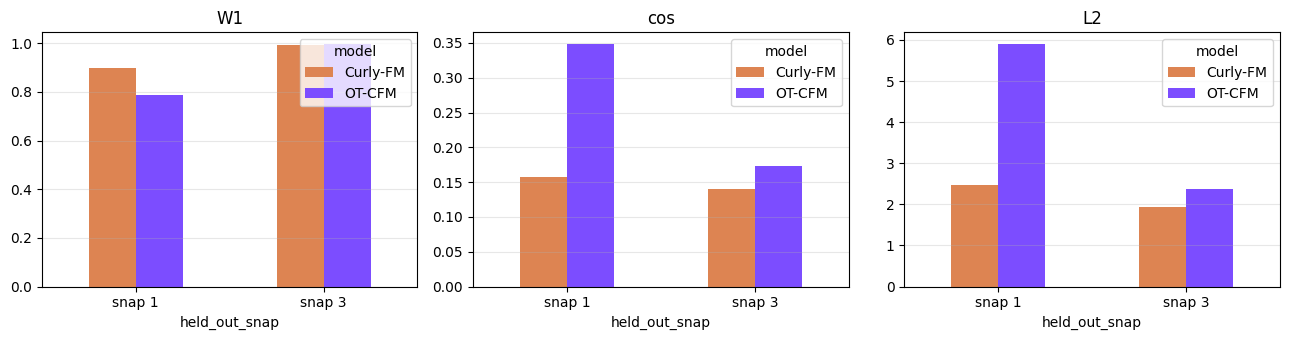

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, m in zip(axes, ["W1", "cos", "L2"]):
    pivot = comp.pivot(index="held_out_snap", columns="model", values=m)
    pivot.plot(kind="bar", ax=ax, color=["#dd8452", "#7c4dff"])
    ax.set_title(m); ax.set_ylabel("")
    ax.set_xticklabels([f"snap {x}" for x in pivot.index], rotation=0)
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()


## « Triche » (méthode exacte du papier) vs version rigoureuse

**Référence** : Curly-FM, Petrović et al., NeurIPS 2025 — arXiv:2510.26645.

**La « triche » = la procédure EXACTE du papier.** Le code officiel trace les trajectoires
en **simulant le champ appris segment par segment**, chaque segment **repartant des vraies
cellules** du snapshot (`node.trajectory(x0 = données[t], t → t+1)`, puis on concatène).
Sur des données **appariées/suivies** (océans : mêmes particules dans le temps) c'est
légitime. Mais sur NLSB les snapshots sont des **échantillons indépendants** (mesure
destructive) : **repartir des vraies données à chaque snapshot réinjecte la vérité-terrain**
et **« connecte les intervalles »** → c'est ça, la triche. Effet de bord : un **jump** à
t=2 (la fin du segment 0→2 ≠ la cellule réelle d'où repart 2→4).

**La version rigoureuse (sans triche) = UNE seule intégration continue** de t=0 à t=4,
**sans jamais réinjecter** les données. C'est la **vraie dynamique** du modèle : pas de jump,
mais elle **dérive** et ne repasse pas exactement par les snapshots.

| | TRICHE (papier, par segments) | SANS TRICHE (continu, rigoureux) |
|---|---|---|
| Construction | ODE par segment, **redémarrage aux données** | **1 seule** ODE 0→4, sans réinjection |
| « Connecte les intervalles » | **oui** (via la vérité-terrain) | non |
| Jump à t=2 | possible (artefact) | non |
| Reflète la vraie dynamique | non (ancrée aux données) | **oui** |

Les deux simulent le **même** champ $v_\theta$ ; seule diffère la **réinjection** des données.


In [31]:
def build_paper_trajs(model, positions, ts_train, n_plot=120, n_steps=100, seed=0):
    '''TRICHE = methode EXACTE du papier : on simule le champ appris SEGMENT PAR SEGMENT,
    chaque segment repartant des VRAIES donnees du snapshot, puis on concatene.
    Sur des marginales independantes (NLSB) cela reinjecte la verite-terrain a chaque
    snapshot ("connecte les intervalles") -> jolies courbes, mais jump possible a t=2.'''
    rng = np.random.RandomState(seed)
    trajs = []
    with torch.no_grad():
        for t in range(len(ts_train) - 1):
            a = ts_train[t]
            n = min(n_plot, positions[a].shape[0])
            i0 = rng.choice(positions[a].shape[0], n, replace=False)
            x0 = torch.from_numpy(positions[a][i0]).float().to(device)
            node = NeuralODE(torch_wrapper(model), solver="euler", sensitivity="adjoint")
            out = node.trajectory(x0, t_span=torch.linspace(t, t + 1, n_steps, device=device))
            trajs.append(out.cpu())
    return torch.cat(trajs, 0).numpy()

def build_honest_trajs(model, positions, ts_train, n_plot=120, n_steps=200, seed=0):
    '''SANS TRICHE (rigoureux) : UNE seule integration ODE de t=0 a t=(len-1), SANS jamais
    reinjecter les donnees -> la vraie dynamique du modele (pas de jump, mais derive libre).'''
    rng = np.random.RandomState(seed)
    s0 = ts_train[0]; n = min(n_plot, positions[s0].shape[0])
    i0 = rng.choice(positions[s0].shape[0], n, replace=False)
    x0 = torch.from_numpy(positions[s0][i0]).float().to(device)
    node = NeuralODE(torch_wrapper(model), solver="dopri5", sensitivity="adjoint")
    with torch.no_grad():
        out = node.trajectory(x0, t_span=torch.linspace(0, len(ts_train) - 1, n_steps, device=device))
    return out.cpu().numpy()


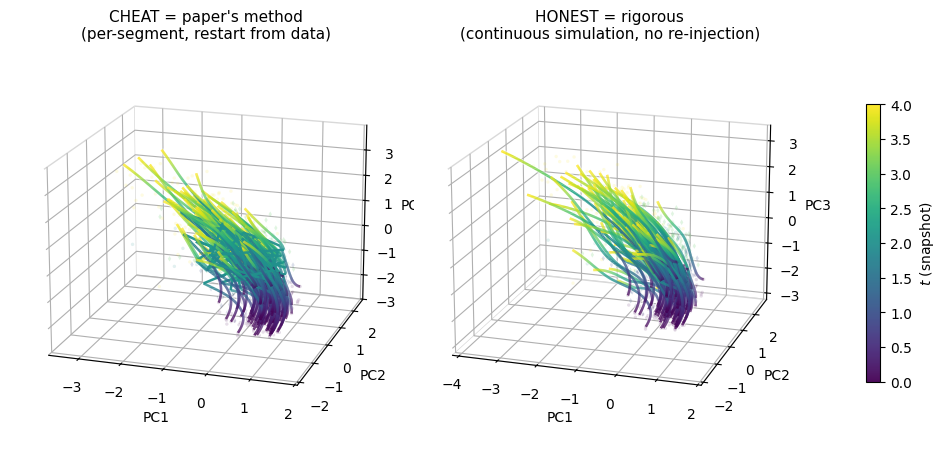

In [32]:
# Memes points de depart a t=0 -> comparaison juste. Les DEUX simulent vel_model ;
# seule difference : la TRICHE (papier) repart des vraies donnees a chaque snapshot.
traj_paper  = build_paper_trajs(vel_model,  positions, TRAIN_TS, n_plot=120)   # TRICHE = methode papier
traj_honest = build_honest_trajs(vel_model, positions, TRAIN_TS, n_plot=120)   # SANS TRICHE = continu

fig = plt.figure(figsize=(13, 6))
ax1 = fig.add_subplot(121, projection="3d")
_draw_traj_panel(ax1, positions, traj_paper, TRAIN_TS, TEST_TS, num_trajectories=120)
ax1.set_title("CHEAT = paper's method\n(per-segment, restart from data)", fontsize=11)

ax2 = fig.add_subplot(122, projection="3d")
lc = _draw_traj_panel(ax2, positions, traj_honest, TRAIN_TS, TEST_TS, num_trajectories=120)
ax2.set_title("HONEST = rigorous\n(continuous simulation, no re-injection)", fontsize=11)

fig.subplots_adjust(wspace=0.03)
cbar = fig.colorbar(lc, ax=[ax1, ax2], shrink=0.6, pad=0.06)
cbar.set_label("$t$ (snapshot)")
plt.show()


## Chiffrer la triche : saut (t=2) vs derive (t=4)

On quantifie l'effet (Wasserstein-1) : la **triche** doit montrer un **saut** a t=2 (elle
reinjecte les vraies donnees) mais une **derive finale plus faible** ; l'**honnete** est
continu (saut = 0) mais **derive davantage** (l'erreur s'accumule sur tout le trajet).


In [33]:
# Saut a t=2 et derive a t=4, mesures en Wasserstein-1.
_W1 = lambda a, b: float(optimal_transport.wasserstein(a, b, power=1))
_node = NeuralODE(torch_wrapper(vel_model), solver="dopri5", sensitivity="adjoint")
_s0 = torch.from_numpy(positions[TRAIN_TS[0]]).float().to(device)
_s2 = torch.from_numpy(positions[TRAIN_TS[1]]).float().to(device)
_s4 = torch.from_numpy(positions[TRAIN_TS[2]]).float().to(device)
with torch.no_grad():
    _A    = _node.trajectory(_s0, t_span=torch.linspace(0, 1, 100, device=device))[-1]  # triche seg 0->2
    _B    = _node.trajectory(_s2, t_span=torch.linspace(1, 2, 100, device=device))[-1]  # triche restart 2->4
    _Cend = _node.trajectory(_s0, t_span=torch.linspace(0, 2, 200, device=device))[-1]  # honnete continu 0->4
jump_cheat   = _W1(_A.cpu(),   _s2.cpu())   # gap teleporte a t=2 (= erreur du modele a t=2)
drift_cheat  = _W1(_B.cpu(),   _s4.cpu())   # erreur finale, triche (repart de la vraie snap2)
drift_honest = _W1(_Cend.cpu(), _s4.cpu())  # erreur finale, honnete (derive tout le long)
print(f"JUMP  at t=2 : cheat = {jump_cheat:.3f}   | honest = 0.000 (continuous)")
print(f"DRIFT at t=4 : cheat = {drift_cheat:.3f}   | honest = {drift_honest:.3f}")
print("-> cheat: jump > 0 but lands closer ; honest: no jump but drifts more (expected trade-off)")


JUMP  at t=2 : cheat = 0.658   | honest = 0.000 (continuous)
DRIFT at t=4 : cheat = 0.698   | honest = 0.803
-> cheat: jump > 0 but lands closer ; honest: no jump but drifts more (expected trade-off)




| Consigne (entretien) | Statut |
|---|---|
| Supprimer la PCA | ✅ on garde les 5 premières composantes brutes |
| 5 premières composantes pour le modèle | ✅ `KEEP_DIMS = 5` |
| 3 premières pour la visualisation | ✅ plots 3D (`VIZ_DIMS = 3`) |
| Learning rate un peu plus grand | ✅ `LR = 5e-4` (était 1e-4) |
| Batch plus grand | ✅ `BATCH = 256` (était 64) |
| 300 cellules par snapshot | ✅ `N_TRACK = 300` |
| GPU impératif | ✅ `device=cuda` (warning si absent) |
| Jusqu'à 3000 itérations | ✅ `N_ITERS = 3000` |
| Train snap 0,2,4 — Val snap 1,3 | ✅ |
| Métriques (W1, cos, L2) | ✅ |
| Objectif : se rapprocher de la FIG 01 de l'article | 🎯 viz 3D des trajectoires |


In [34]:
# ===== Rapport final : marque le run comme reussi =====
import datetime
with open(REPORT, "a", encoding="utf-8") as fh:
    fh.write("\nstatus : SUCCES -- aucune erreur d'execution\n")
    fh.write(f"fin    : {datetime.datetime.now():%Y-%m-%d %H:%M:%S}\n")
    try:
        fh.write(f"  OT-CFM   W1 moyen = {res_ot['W1'].mean():.4f}\n")
        fh.write(f"  Curly-FM W1 moyen = {res_cf['W1'].mean():.4f}\n")
    except Exception:
        pass

print("=" * 68)
print("OK -- aucune erreur d'execution detectee.")
print("Resultats : logs/nlsb/held_out_metrics.csv  +  figures ci-dessus")
print("Rapport   :", REPORT)
print("=" * 68)


OK -- aucune erreur d'execution detectee.
Resultats : logs/nlsb/held_out_metrics.csv  +  figures ci-dessus
Rapport   : /kaggle/working/run_report.txt
